## Convolution Operation in CNNs

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

### Create a small image and filter

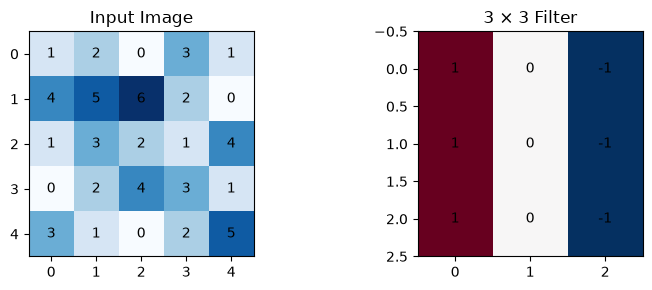

In [2]:
image = np.array([
    [1, 2, 0, 3, 1],
    [4, 5, 6, 2, 0],
    [1, 3, 2, 1, 4],
    [0, 2, 4, 3, 1],
    [3, 1, 0, 2, 5]
], dtype=np.float32)

kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
], dtype=np.float32)

fig, axes = plt.subplots(1, 2, figsize=(8, 3))

axes[0].imshow(image, cmap="Blues")
axes[0].set_title("Input Image")
axes[1].imshow(kernel, cmap="RdBu_r")
axes[1].set_title("3 × 3 Filter")

for ax in axes:
    for i in range(image.shape[0] if ax == axes[0] else kernel.shape[0]):
        for j in range(image.shape[1] if ax == axes[0] else kernel.shape[1]):
            value = image[i, j] if ax == axes[0] else kernel[i, j]
            ax.text(j, i, f"{value:g}", ha="center", va="center")

plt.tight_layout()
plt.show()

### Perform Convolution Manually

In [3]:
def manual_convolution(image, kernel, stride=1):
    H, W = image.shape
    kH, kW = kernel.shape

    out_H = (H - kH) // stride + 1
    out_W = (W - kW) // stride + 1

    output = np.zeros((out_H, out_W))

    for i in range(out_H):
        for j in range(out_W):
            region = image[
                i*stride:i*stride+kH,
                j*stride:j*stride+kW
            ]

            output[i, j] = np.sum(region * kernel)

    return output

feature_map = manual_convolution(image, kernel)

print("Feature map:\n", feature_map)
print("Output shape:", feature_map.shape)

Feature map:
 [[-2.  4.  3.]
 [-7.  4.  7.]
 [-2.  0. -4.]]
Output shape: (3, 3)


### Understand one convolution step

In [4]:
region = image[:3, :3]
multiplication = region * kernel

print("Image region:\n", region)
print("\nFilter:\n", kernel)
print("\nElement-wise multiplication:\n", multiplication)
print("\nSum =", multiplication.sum())

Image region:
 [[1. 2. 0.]
 [4. 5. 6.]
 [1. 3. 2.]]

Filter:
 [[ 1.  0. -1.]
 [ 1.  0. -1.]
 [ 1.  0. -1.]]

Element-wise multiplication:
 [[ 1.  0. -0.]
 [ 4.  0. -6.]
 [ 1.  0. -2.]]

Sum = -2.0


### Visualize feature map

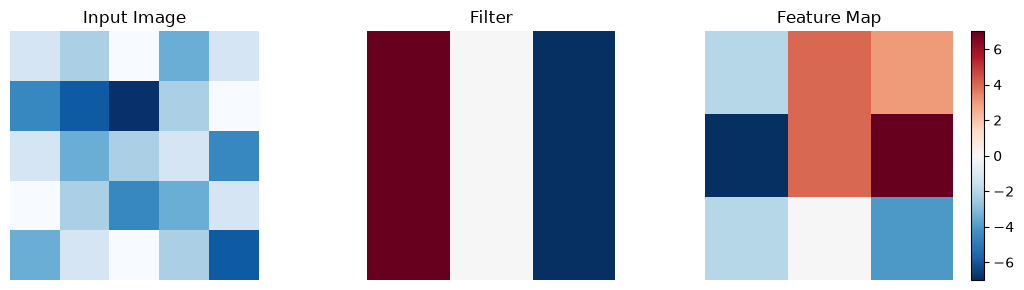

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))

axes[0].imshow(image, cmap="Blues")
axes[0].set_title("Input Image")

axes[1].imshow(kernel, cmap="RdBu_r")
axes[1].set_title("Filter")

im = axes[2].imshow(feature_map, cmap="RdBu_r")
axes[2].set_title("Feature Map")
plt.colorbar(im, ax=axes[2])

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Tensorflow

In [6]:
image_tf = tf.constant(image[None, :, :, None])
kernel_tf = tf.constant(kernel[:, :, None, None])

output_tf = tf.nn.conv2d(
    image_tf,
    kernel_tf,
    strides=1,
    padding="VALID"
)

tf_feature_map = output_tf.numpy()[0, :, :, 0]

print("Manual result:\n", feature_map)
print("\nTensorFlow result:\n", tf_feature_map)

print("\nSame result:", np.allclose(feature_map, tf_feature_map))

Manual result:
 [[-2.  4.  3.]
 [-7.  4.  7.]
 [-2.  0. -4.]]

TensorFlow result:
 [[-2.  4.  3.]
 [-7.  4.  7.]
 [-2.  0. -4.]]

Same result: True


### Different strides

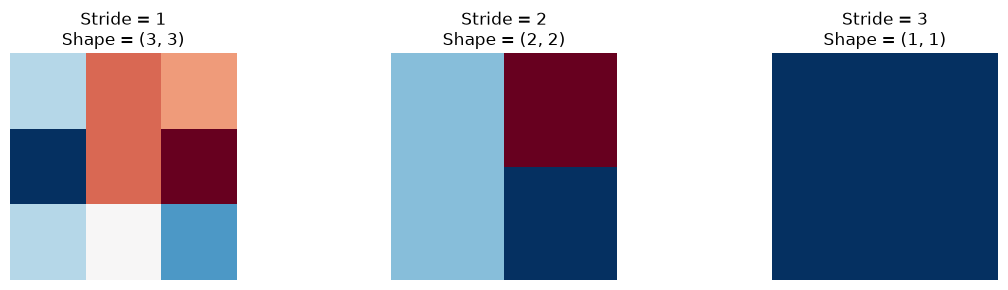

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, stride in zip(axes, [1, 2, 3]):
    result = manual_convolution(image, kernel, stride=stride)

    ax.imshow(result, cmap="RdBu_r")
    ax.set_title(f"Stride = {stride}\nShape = {result.shape}")
    ax.axis("off")

plt.tight_layout()
plt.show()